# L1 vs L2 regularisation in pytem

`pytem.invert(..., regularization=)` penalises the contrasts between neighbouring layers:

- `'l2'`: squared contrasts, which gives smooth models
- `'l1'`: absolute contrasts, which gives blocky models

In [1]:
import sys
from pathlib import Path

import numpy as np

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pytem').is_dir())))
from pytem import fwd_circle_central, invert, plot_model

A 3-layer earth with a conductive middle layer, 3 % noise.

In [2]:
radius, times = 20, np.logspace(-5, -2, 25)
true_thk, true_rho = [20, 30], [100, 10, 100]

d = -fwd_circle_central(true_thk, true_rho, radius, times, transform='dlf', use_numba=True, use_cuda=False)
noise = 0.03 * d
d_obs = d + np.random.default_rng(1).normal(0, noise)

Invert with 20 layers; only `regularization` changes.

In [3]:
thk = np.geomspace(2, 10, 19)
args = dict(obs_data=d_obs, times=times, noise_std=noise, thicknesses=thk, log_resistivities=np.log(np.full(20, 50.)),
            tx_size=radius, transform='dlf', max_noise_frac=0.0, maxit=30, step_backtrack='auto', use_cuda=False)

l2 = invert(regularization='l2', **args)
l1 = invert(regularization='l1', l1_beta = 0.0005, l1_beta_step=1 / 3, **args)

[invert] geometry=circle_central, transform=dlf, fwd_backend=numba, jac_backend=numba, analytical_j=True, waveform=False
Observed data: Mean Apparent Resistivity = 39.0 Ohm.m (over 25/25 valid gates)


Alpha start = 2448.914
Iteration   1:  RMS = 28.53


    Alpha = 2448.91,  RMS = 20.55


    Alpha = 1896.10,  RMS = 21.57
    RMS increased - stopping alpha search early.
Iteration   2:  RMS = 20.55


    Alpha = 3162.89,  RMS = 5.86


    Alpha = 2448.91,  RMS = 5.29


... (44 outputs left out)

    Alpha = 88.01,  RMS = 1.53


    Alpha = 68.14,  RMS = 1.34
Iteration   7:  RMS = 1.34


    Alpha = 88.01,  RMS = 1.07


    Alpha = 68.14,  RMS = 0.96
    RMS below 1 - stopping ladder.
Iteration   8:  RMS = 0.96
  RMS <= 1 - converged.


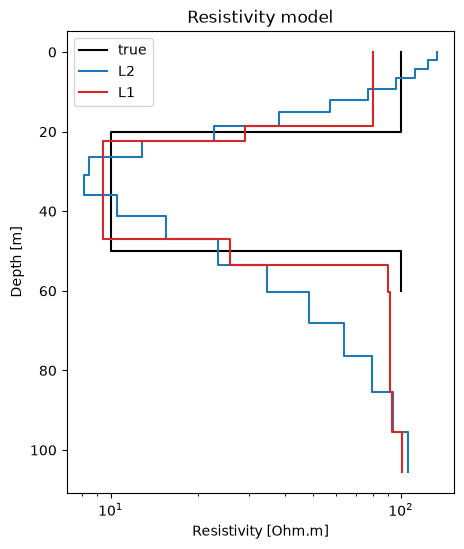

In [4]:
ax = plot_model(true_thk, true_rho, label='true', color='k', figsize=(5, 6))
plot_model(thk, l2['resistivities'], ax=ax, label='L2', color='C0')
plot_model(thk, l1['resistivities'], ax=ax, label='L1', color='C3')
ax.legend();

Both fit the data. L2 gives a smooth conductive zone, L1 a flat-sided block.